# Transferir evidência com dados da NASA: análogos climáticos, aptidão e ciclo de plantio

**Pergunta central:** a literatura de rotação vem de climas diferentes do sertão. **De quais estudos podemos usar os
números no Ceará, e no mundo, e com que peso?** E, para cada lugar, **o que plantar e quando**?

Este notebook aprofunda as conclusões da seção 18 do estudo principal:
1. **Robustez:** a ordem dos análogos depende de quais variáveis climáticas usamos?
2. **Mapa de análogos no Ceará:** para cada um dos 184 municípios, o estudo de clima mais parecido e a confiança da transferência.
3. **O sertão no mundo:** onde, no planeta, o clima se parece com o do Sertão Central, e onde o produto vale igual.
4. **Aptidão das culturas nos análogos:** o GAEZ confirma que as mesmas culturas cabem nos lugares parecidos?
5. **Ciclo de plantio:** o início da estação pela chuva (IMERG) e pelo verde (MODIS), por município, de 1998 a 2026,
   e o efeito do El Niño.
6. **Como isso entra no motor da QUADRA.**

**Dados:**
- NASA POWER (climatologia, API, qualquer ponto do planeta);
- NASA GPM IMERG V07 (diário, 0,1°);
- NASA MODIS MOD13Q1 (NDVI, 16 dias);
- FAO GAEZ v4 (aptidão);
- IBGE (malha municipal);
- NOAA (ONI).

Preparação: `scripts/preparar_analogos_aprofundado.py` e `scripts/analogos_climaticos_artigos.py`.

In [1]:
import sys
import warnings

sys.path.insert(0, r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\scripts")
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from comum import DADOS, ceara_gdf, municipios_ce_gdf, paises_gdf

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
D_ART = DADOS / "analogos_artigos"
D_APR = DADOS / "analogos_aprofundado"
VARS = ["chuva_anual_mm", "sazonalidade_walsh", "meses_umidos", "aridez_P_ET0", "tmax_estacao_umida", "tmax_mes_mais_quente"]
ROT = {"chuva_anual_mm": "chuva anual", "sazonalidade_walsh": "sazonalidade", "meses_umidos": "meses úmidos",
       "aridez_P_ET0": "aridez P/ET0", "tmax_estacao_umida": "Tmax estação úmida", "tmax_mes_mais_quente": "Tmax mês mais quente"}
A = pd.read_csv(D_ART / "assinaturas.csv")
SIT = A[A.grupo != "Ceará (alvo)"].reset_index(drop=True)
CE12 = A[A.grupo == "Ceará (alvo)"].reset_index(drop=True)
MU = A[VARS].mean()
SD = A[VARS].std()


def z(df):
    return (df[VARS] - MU) / SD


def dist(alvo_z, fontes_z, pesos=None):
    w = np.ones(len(VARS)) if pesos is None else np.asarray(pesos)
    return np.sqrt((((fontes_z.values - alvo_z.values[None, :]) ** 2) * w).sum(1) * len(VARS) / w.sum())


print(f"{len(SIT)} lugares de artigos; {len(CE12)} pontos de referência do Ceará")

20 lugares de artigos; 12 pontos de referência do Ceará


## 1. A ordem dos análogos é robusta?
Três testes, para o Sertão Central (Quixadá):
- **(a) Tirar uma variável de cada vez:** a ordem muda?
- **(b) Distância de Mahalanobis:** desconta a correlação entre as variáveis (chuva e aridez andam juntas).
- **(c) 2.000 sorteios de pesos aleatórios** (Dirichlet): com que frequência cada lugar aparece entre os 3 mais parecidos?

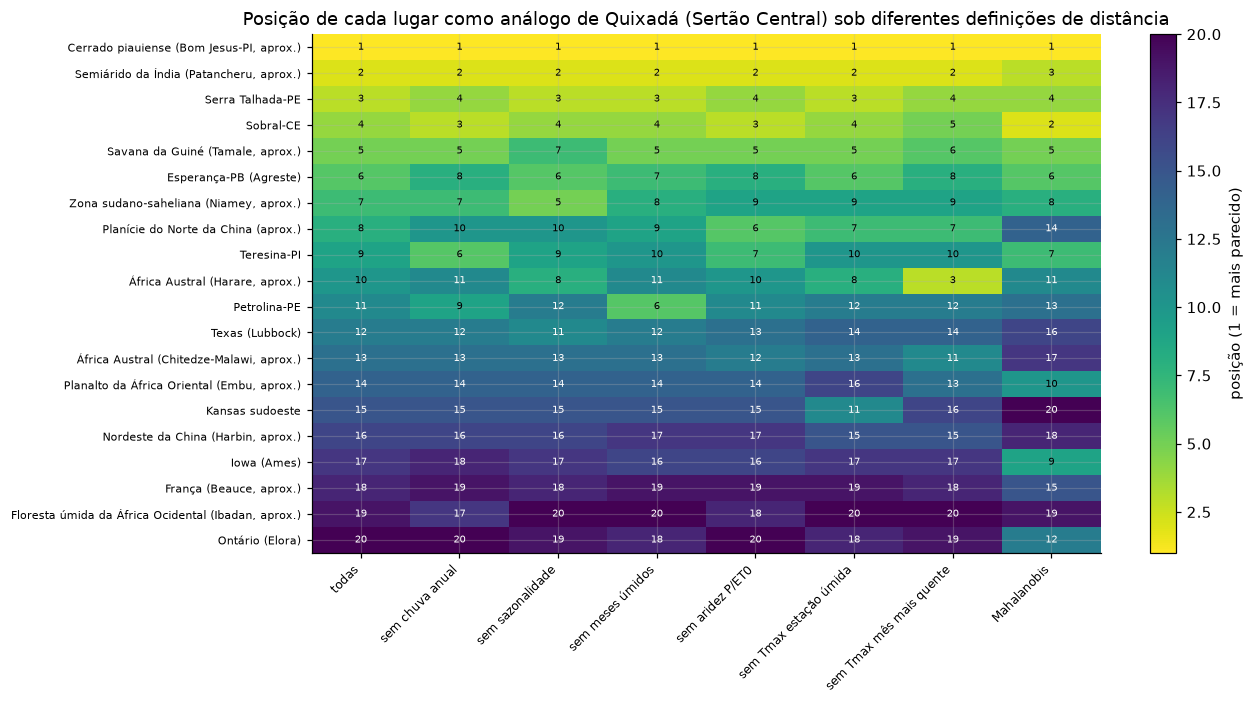

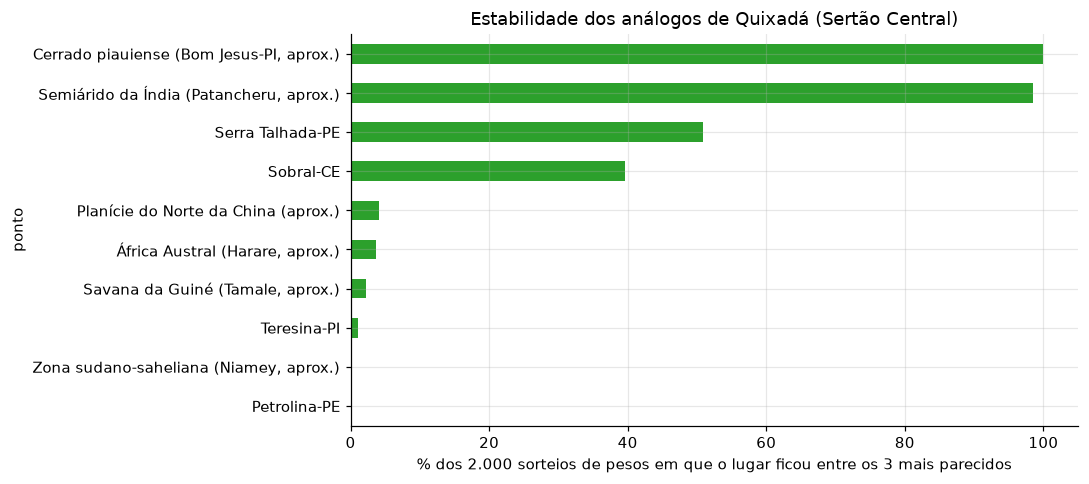

,% no top-3
ponto,
"Cerrado piauiense (Bom Jesus-PI, aprox.)",100.0
"Semiárido da Índia (Patancheru, aprox.)",98.6
Serra Talhada-PE,50.8
Sobral-CE,39.6
Planície do Norte da China (aprox.),4.0
"África Austral (Harare, aprox.)",3.6
"Savana da Guiné (Tamale, aprox.)",2.2
Teresina-PI,1.1


Concordância da ordem com a distância completa (tau de Kendall): {'sem chuva anual': np.float64(0.91), 'sem sazonalidade': np.float64(0.92), 'sem meses úmidos': np.float64(0.92), 'sem aridez P/ET0': np.float64(0.92), 'sem Tmax estação úmida': np.float64(0.88), 'sem Tmax mês mais quente': np.float64(0.85), 'Mahalanobis': np.float64(0.65)}


In [2]:
alvo = "CE: Quixadá (Sertão Central)"
za = z(A[A.ponto == alvo]).iloc[0]
zs = z(SIT)
base = pd.Series(dist(za, zs), index=SIT.ponto).sort_values()
linhas = {"todas": base.rank()}
for v in VARS:
    w = [0 if x == v else 1 for x in VARS]
    linhas[f"sem {ROT[v]}"] = pd.Series(dist(za, zs, w), index=SIT.ponto).rank()
# Mahalanobis
X = A[VARS].values
cov = np.cov(((X - X.mean(0)) / X.std(0)).T)
icov = np.linalg.pinv(cov)
dz = zs.values - za.values[None, :]
mah = np.sqrt(np.einsum("ij,jk,ik->i", dz, icov, dz))
linhas["Mahalanobis"] = pd.Series(mah, index=SIT.ponto).rank()
R = pd.DataFrame(linhas).loc[base.index].astype(int)
fig, ax = plt.subplots(figsize=(12, 6.5))
im = ax.imshow(R.values, cmap="viridis_r", aspect="auto")
ax.set_yticks(range(len(R)))
ax.set_yticklabels(R.index, fontsize=7)
ax.set_xticks(range(R.shape[1]))
ax.set_xticklabels(R.columns, rotation=45, ha="right", fontsize=8)
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        ax.text(j, i, R.values[i, j], ha="center", va="center", fontsize=6.5, color="w" if R.values[i, j] > 10 else "k")
plt.colorbar(im, label="posição (1 = mais parecido)")
ax.set_title(f"Posição de cada lugar como análogo de {alvo.replace('CE: ', '')} sob diferentes definições de distância")
plt.tight_layout()
plt.show()

# (c) pesos aleatórios
rng = np.random.default_rng(42)
top3 = pd.Series(0, index=SIT.ponto, dtype=float)
for _ in range(2000):
    w = rng.dirichlet(np.ones(len(VARS)))
    d = pd.Series(dist(za, zs, w), index=SIT.ponto)
    top3[d.nsmallest(3).index] += 1
top3 = (top3 / 2000 * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.5))
top3.head(10)[::-1].plot.barh(ax=ax, color="tab:green")
ax.set_xlabel("% dos 2.000 sorteios de pesos em que o lugar ficou entre os 3 mais parecidos")
ax.set_title(f"Estabilidade dos análogos de {alvo.replace('CE: ', '')}")
plt.tight_layout()
plt.show()
display(top3.head(8).round(1).to_frame("% no top-3"))
from scipy.stats import kendalltau
tau = {c: round(kendalltau(R["todas"], R[c])[0], 2) for c in R.columns if c != "todas"}
print("Concordância da ordem com a distância completa (tau de Kendall):", tau)

**Leitura:** um análogo só entra no motor com peso alto se ficar entre os primeiros em quase todos os cenários. Lugares
que só aparecem bem numa definição de distância entram com cautela no recibo.

## 2. Mapa de análogos no Ceará: qual literatura vale em cada município?
Para cada um dos 184 municípios, calculamos a assinatura climática do NASA POWER (pelo ponto interno do município) e o
lugar de artigo mais parecido. A **confiança da transferência** é o peso w = exp(−d²/2) do melhor análogo: perto de 1,
o estudo foi feito num clima muito parecido; perto de 0, não há estudo parecido.

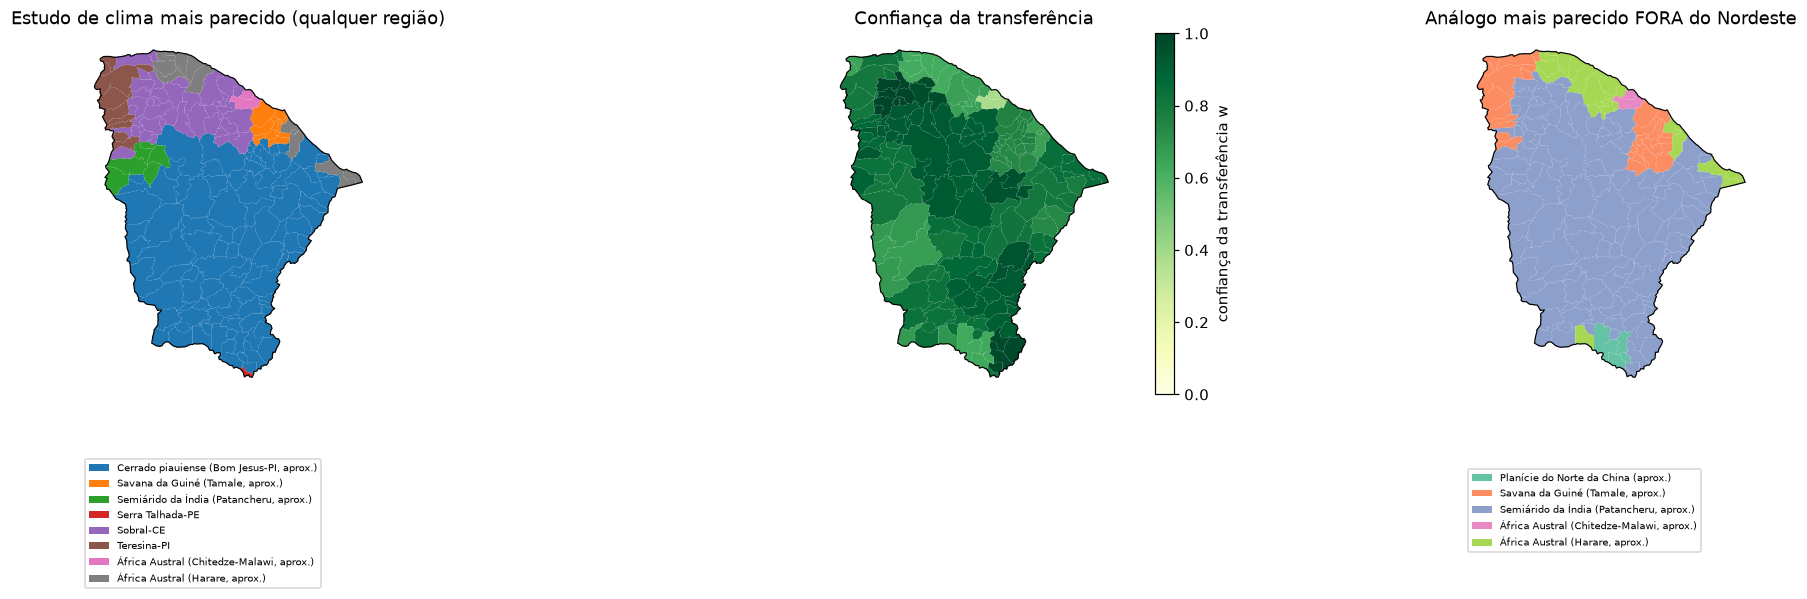

,municipios,confianca_media,analogo_mais_comum,global_mais_comum,dist_global_media
mesorregiao,,,,,
Centro-Sul Cearense,14,0.90,"Cerrado piauiense (Bom Jesus-PI, aprox.)","Semiárido da Índia (Patancheru, aprox.)",0.72
Jaguaribe,21,0.83,"Cerrado piauiense (Bom Jesus-PI, aprox.)","Semiárido da Índia (Patancheru, aprox.)",0.92
Metropolitana de Fortaleza,11,0.75,"Savana da Guiné (Tamale, aprox.)","Savana da Guiné (Tamale, aprox.)",0.77
Noroeste Cearense,47,0.87,Sobral-CE,"Semiárido da Índia (Patancheru, aprox.)",0.83
Norte Cearense,36,0.73,Sobral-CE,"Savana da Guiné (Tamale, aprox.)",0.92
Sertões Cearenses,30,0.82,"Cerrado piauiense (Bom Jesus-PI, aprox.)","Semiárido da Índia (Patancheru, aprox.)",0.90
Sul Cearense,25,0.82,"Cerrado piauiense (Bom Jesus-PI, aprox.)","Semiárido da Índia (Patancheru, aprox.)",0.97


Distribuição do melhor análogo (nº de municípios):


,municípios
melhor_analogo,
"Cerrado piauiense (Bom Jesus-PI, aprox.)",102
Sobral-CE,40
"Savana da Guiné (Tamale, aprox.)",13
"África Austral (Harare, aprox.)",11
Teresina-PI,9
"Semiárido da Índia (Patancheru, aprox.)",6
"África Austral (Chitedze-Malawi, aprox.)",2
Serra Talhada-PE,1


In [3]:
M = pd.read_csv(D_APR / "ceara_mun_assinaturas.csv", dtype={"cod": str})
zm = z(M)
dm = np.array([dist(zm.iloc[i], zs) for i in range(len(M))])
M["melhor_analogo"] = SIT.ponto.values[dm.argmin(1)]
M["grupo_analogo"] = SIT.grupo.values[dm.argmin(1)]
M["dist_melhor"] = dm.min(1)
M["confianca"] = np.exp(-M.dist_melhor ** 2 / 2)
# melhor análogo FORA do Nordeste (para ver de que literatura global cada região puxa)
fora = ~SIT.grupo.str.startswith("Nordeste")
M["melhor_global"] = SIT.ponto.values[fora][dm[:, fora.values].argmin(1)]
M["dist_global"] = dm[:, fora.values].min(1)
geo = municipios_ce_gdf().assign(cod=lambda g: g.codarea.astype(str)).merge(M, on="cod")
fig, axs = plt.subplots(1, 3, figsize=(19, 6.5))
geo.plot(column="melhor_analogo", ax=axs[0], legend=True, categorical=True, cmap="tab10",
         legend_kwds={"fontsize": 6.5, "loc": "lower left", "bbox_to_anchor": (0, -0.55)})
axs[0].set_title("Estudo de clima mais parecido (qualquer região)")
geo.plot(column="confianca", ax=axs[1], cmap="YlGn", vmin=0, vmax=1, legend=True, legend_kwds={"label": "confiança da transferência w"})
axs[1].set_title("Confiança da transferência")
geo.plot(column="melhor_global", ax=axs[2], legend=True, categorical=True, cmap="Set2",
         legend_kwds={"fontsize": 6.5, "loc": "lower left", "bbox_to_anchor": (0, -0.45)})
axs[2].set_title("Análogo mais parecido FORA do Nordeste")
for a in axs:
    ceara_gdf().boundary.plot(ax=a, color="k", lw=0.8)
    a.set_axis_off()
plt.tight_layout()
plt.show()
resumo = M.groupby("mesorregiao").agg(municipios=("cod", "count"), confianca_media=("confianca", "mean"),
                                       analogo_mais_comum=("melhor_analogo", lambda s: s.value_counts().index[0]),
                                       global_mais_comum=("melhor_global", lambda s: s.value_counts().index[0]),
                                       dist_global_media=("dist_global", "mean")).round(2)
display(resumo)
print("Distribuição do melhor análogo (nº de municípios):")
display(M.melhor_analogo.value_counts().to_frame("municípios"))

**Leitura:**
- **As regiões do Ceará não puxam a mesma literatura.**
  - O **Cerrado piauiense** é o melhor análogo em 102 municípios (Centro-Sul, Jaguaribe, Sertões e Sul).
  - **Sobral**, em 40 (Noroeste e Norte).
  - A **Savana da Guiné (Tamale)**, em 13 (Região Metropolitana de Fortaleza).
  - A **África Austral (Harare)** fica só com 11.
  - Fora do Nordeste, o análogo mais comum é o **semiárido da Índia (Patancheru)** em 5 das 7 mesorregiões. Na
    Metropolitana e no Norte, é a Savana da Guiné.
- **A confiança é alta em todas as mesorregiões** (w médio de 0,73 no Norte a 0,90 no Centro-Sul). A Região
  Metropolitana de Fortaleza (0,75) não é mais o ponto fraco.
- **No produto,** o recibo de cada estratégia mostra o estudo análogo **do município do usuário**, não um número único
  para o estado.

## 3. O sertão no mundo: onde o clima se parece com o do Sertão Central?
Assinatura climática do NASA POWER numa grade global de 6° (pontos de terra) e a distância até Quixadá. Mostra:
- **onde mais o produto se aplica do mesmo jeito** (mercado global da ferramenta);
- **onde procurar mais literatura de rotação** que se transfira para o sertão.

387 pontos de terra; 2 com distância < 1 do Sertão Central


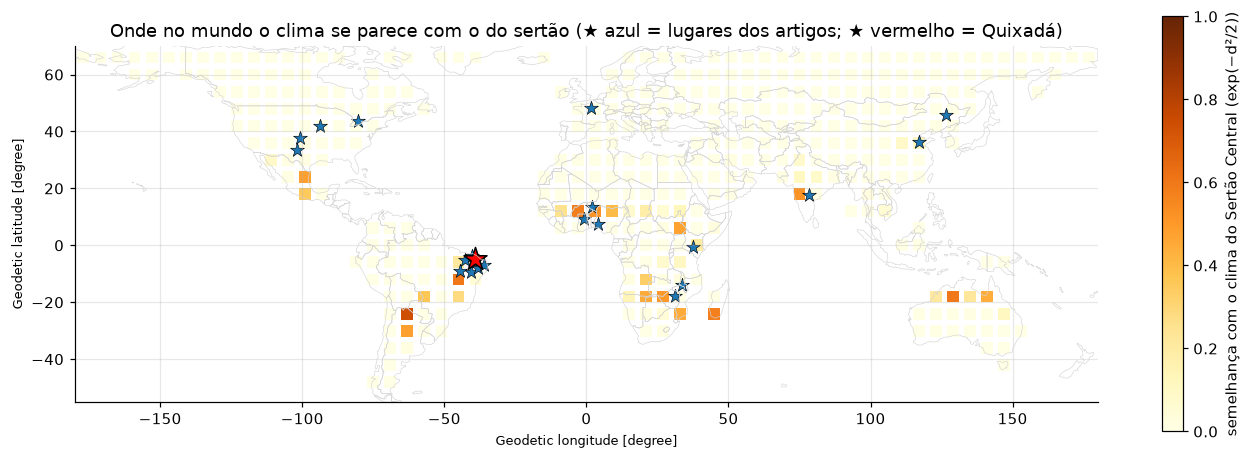

,lat,lon,chuva_anual_mm,aridez_P_ET0,meses_umidos,sazonalidade_walsh,dist_sertao
69,-6,-39,782.0,0.34,5,0.83,0.22
22,-24,-63,816.0,0.51,5,0.78,0.77
55,-12,-45,893.0,0.44,6,0.79,1.01
47,-18,129,733.0,0.29,4,0.98,1.01
102,12,-3,925.0,0.41,4,0.93,1.04
29,-24,45,846.0,0.42,4,0.72,1.05
126,18,75,581.0,0.29,5,0.95,1.15
103,12,3,707.0,0.31,4,0.99,1.15
43,-18,27,638.0,0.31,4,1.00,1.17
9,-30,-63,784.0,0.48,4,0.64,1.21


In [4]:
G = pd.read_csv(D_APR / "global_assinaturas.csv")
zg = (G[VARS] - MU) / SD
G["dist_sertao"] = dist(za, zg)
G["similaridade"] = np.exp(-G.dist_sertao ** 2 / 2)
print(f"{len(G)} pontos de terra; {int((G.dist_sertao < 1.0).sum())} com distância < 1 do Sertão Central")
fig, ax = plt.subplots(figsize=(15, 7))
paises_gdf().boundary.plot(ax=ax, color="lightgray", lw=0.4)
sc = ax.scatter(G.lon, G.lat, c=G.similaridade, cmap="YlOrBr", s=60, marker="s", vmin=0, vmax=1, edgecolors="none")
plt.colorbar(sc, ax=ax, label="semelhança com o clima do Sertão Central (exp(−d²/2))", shrink=0.7)
for _, s in SIT.iterrows():
    ax.scatter(s.lon, s.lat, marker="*", s=90, c="tab:blue", edgecolors="k", lw=0.4)
q = A[A.ponto == alvo].iloc[0]
ax.scatter(q.lon, q.lat, marker="*", s=250, c="red", edgecolors="k")
ax.set_xlim(-180, 180)
ax.set_ylim(-55, 70)
ax.set_title("Onde no mundo o clima se parece com o do sertão (★ azul = lugares dos artigos; ★ vermelho = Quixadá)")
plt.show()
top = G.nsmallest(20, "dist_sertao")[["lat", "lon", "chuva_anual_mm", "aridez_P_ET0", "meses_umidos", "sazonalidade_walsh", "dist_sertao"]]
display(top.round(2))

**Leitura:**
- **Só 2 dos 387 pontos de terra têm distância < 1 do Sertão Central, e 19 têm distância < 1,5.** O clima do sertão
  é raro no planeta. Os mais parecidos são:
  - o próprio Ceará (−6, −39; d 0,22);
  - o **Chaco argentino** (−24, −63; d 0,77), o único outro ponto com d < 1;
  - o **Oeste da Bahia** (−12, −45; 1,01) e o **norte da Austrália** (−18, 129; 1,01);
  - **Burkina Faso** (12, −3; 1,04) e o **sudoeste de Madagascar** (−24, 45; 1,05);
  - o **Deccan na Índia** (18, 75; 1,15).
  - Logo depois vêm o norte do Benim, o Zimbábue, o Chaco argentino mais ao sul (−30, −63), o México, o Sudão do Sul,
    a Namíbia, Moçambique, o norte da Nigéria, o Pantanal (−18, −57) e Angola. O norte de Minas (−18, −45) fica logo
    acima, com d 1,59.
  - **É nessas savanas tropicais de estação chuvosa curta que vale procurar experimentos de rotação** para o catálogo.
- **Ressalva:** o **norte da China** (36–42°N) tem chuva de monção concentrada no verão, que imita a sazonalidade do
  sertão. Com a Tmax média (e não o recorde do mês), ele fica fora dos 20 mais parecidos: todos os 20 estão entre 30°S
  e 24°N. **Próxima melhoria:** incluir a Tmin do mês mais frio (geada), para separar de vez as monções temperadas das
  tropicais.
- **Para a ferramenta,** essas regiões são onde a QUADRA funciona com a mesma lógica (portões, análogos e IMERG + SMAP)
  sem nenhuma mudança: uma prova concreta do "produto global".
- Grade de 6°: o mapa é indicativo. Para cada usuário, o produto calcula a assinatura do próprio talhão.

## 4. As mesmas culturas cabem nos análogos? (FAO GAEZ v4)
Índice de aptidão (0–100, sequeiro, insumo baixo e alto) de 15 culturas, amostrado em cada lugar de artigo e nos 12
pontos do Ceará. **Se o análogo climático também tem o mesmo perfil de aptidão, a transferência da evidência fica mais
segura.**

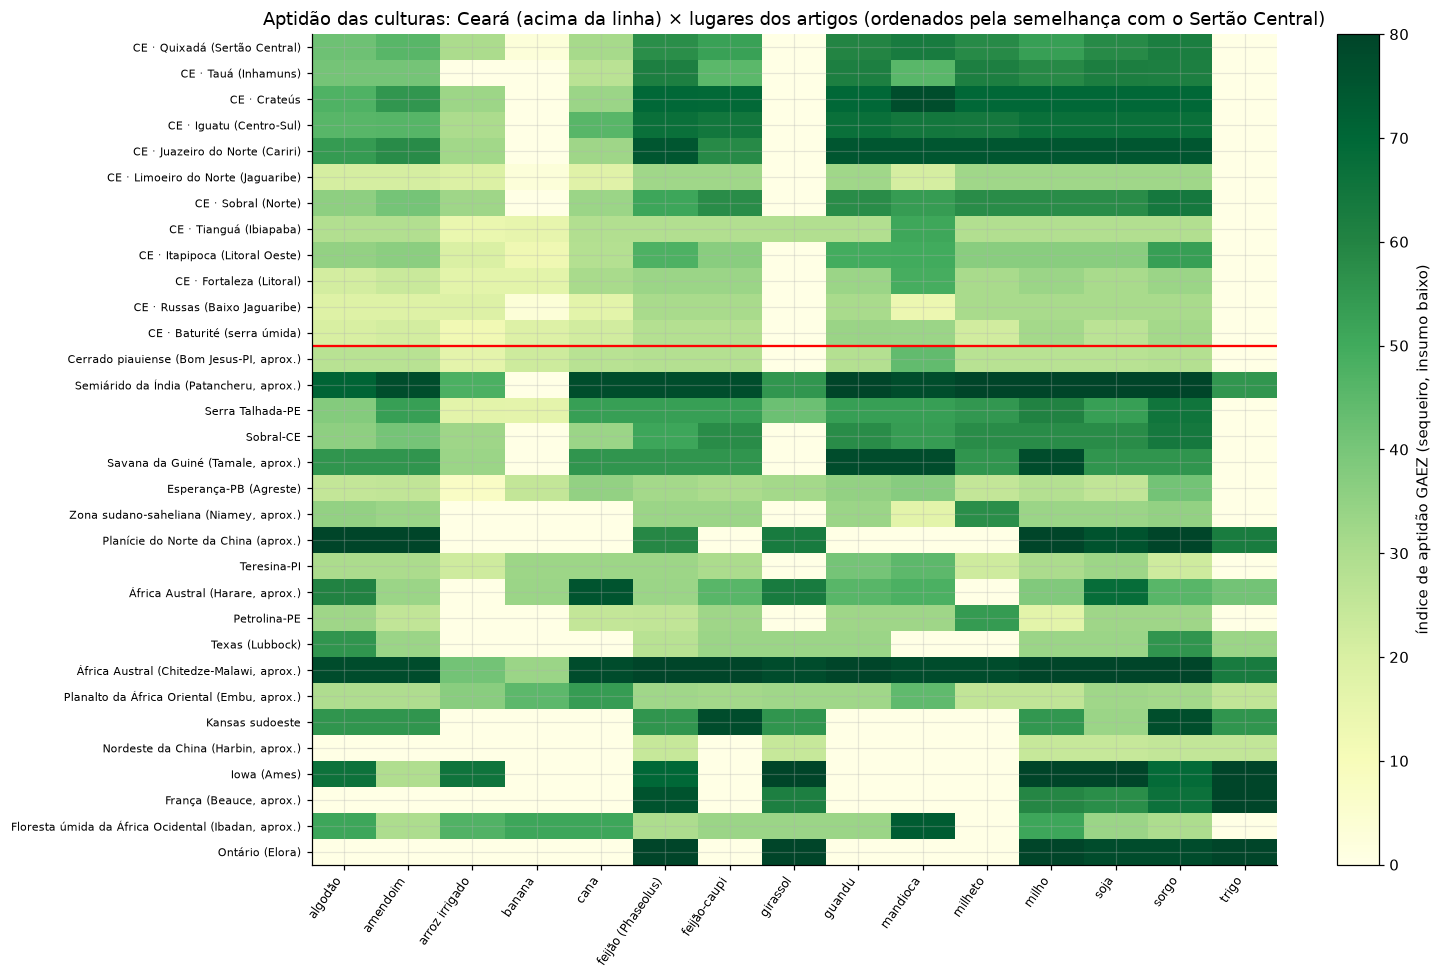

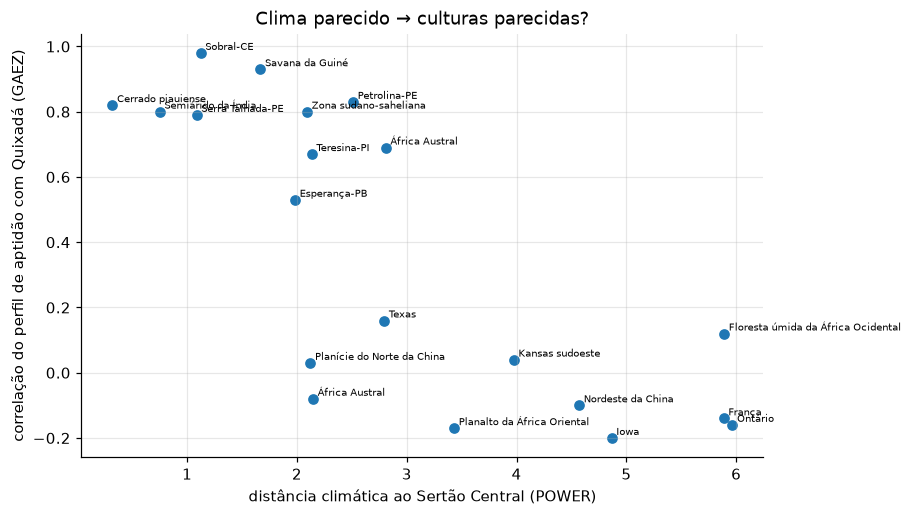

,distância climática,correlação do perfil de aptidão
ponto,,
"Cerrado piauiense (Bom Jesus-PI, aprox.)",0.320128,0.82
"Semiárido da Índia (Patancheru, aprox.)",0.751557,0.80
Serra Talhada-PE,1.086452,0.79
Sobral-CE,1.123925,0.98
"Savana da Guiné (Tamale, aprox.)",1.667792,0.93
Esperança-PB (Agreste),1.983284,0.53
"Zona sudano-saheliana (Niamey, aprox.)",2.092449,0.80
Planície do Norte da China (aprox.),2.122843,0.03
Teresina-PI,2.135889,0.67


Correlação de Spearman entre distância climática e semelhança de aptidão: -0.76


In [5]:
GZ = pd.read_csv(D_APR / "gaez_sitios.csv")
baixo = GZ[GZ.insumo == "Low"].pivot_table(index="ponto", columns="cultura", values="SI")
ordem = [p for p in list(CE12.ponto) + list(base.index) if p in baixo.index]
H = baixo.loc[ordem]
fig, ax = plt.subplots(figsize=(14, 9))
im = ax.imshow(H.values, cmap="YlGn", aspect="auto", vmin=0, vmax=80)
ax.set_xticks(range(H.shape[1]))
ax.set_xticklabels(H.columns, rotation=55, ha="right", fontsize=8)
ax.set_yticks(range(H.shape[0]))
ax.set_yticklabels([p.replace("CE: ", "CE · ") for p in H.index], fontsize=7)
ax.axhline(len(CE12) - 0.5, color="r", lw=1.5)
plt.colorbar(im, label="índice de aptidão GAEZ (sequeiro, insumo baixo)")
ax.set_title("Aptidão das culturas: Ceará (acima da linha) × lugares dos artigos (ordenados pela semelhança com o Sertão Central)")
plt.tight_layout()
plt.show()

# correlação do perfil de aptidão entre Quixadá e cada lugar de artigo, contra a distância climática
q_perfil = H.loc[alvo]
corr = H.loc[[p for p in base.index if p in H.index]].apply(lambda r: r.corr(q_perfil), axis=1)
C = pd.DataFrame({"distância climática": base.reindex(corr.index), "correlação do perfil de aptidão": corr.round(2)})
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(C["distância climática"], C["correlação do perfil de aptidão"])
for p, r in C.iterrows():
    ax.annotate(p.split(" (")[0], (r["distância climática"], r["correlação do perfil de aptidão"]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("distância climática ao Sertão Central (POWER)")
ax.set_ylabel("correlação do perfil de aptidão com Quixadá (GAEZ)")
ax.set_title("Clima parecido → culturas parecidas?")
plt.show()
display(C.sort_values("distância climática"))
print("Correlação de Spearman entre distância climática e semelhança de aptidão:",
      round(C.corr("spearman").iloc[0, 1], 2))

**Leitura:**
- **O clima é um bom guia:** quanto mais longe no clima, menos parecido o perfil de culturas (Spearman −0,76).
  - Os análogos do Nordeste têm o perfil de aptidão quase igual ao de Quixadá: Sobral 0,98, Cerrado piauiense 0,82,
    Serra Talhada 0,79.
  - Os 5 lugares mais parecidos no clima (d de 0,32 a 1,67) têm todos perfil parecido (de 0,79 a 0,98). Entre eles
    estão o semiárido da Índia (d 0,75; 0,80) e a Savana da Guiné (d 1,67; 0,93).
  - Iowa, França, Ontário e o NE da China têm perfis diferentes (correlação ≤ 0,03).
- **Harare deixou de ser a exceção:** agora ele está longe no clima (d 2,15, 10º lugar) e não conta como análogo. O
  perfil de culturas continua diferente (correlação −0,08), provavelmente pela altitude, que deixa o lugar mais fresco.
  - Os desvios ficam a meia distância: a Planície do Norte da China (d 2,12; 0,03) e Harare têm perfil diferente;
    Niamey (d 2,09; 0,80) e Petrolina (d 2,51; 0,83) têm perfil parecido.
  - **Transferir de lugares assim exige checar cultura a cultura.**
- A tabela mostra, cultura a cultura, onde a aptidão do análogo difere da do sertão. **A evidência de uma cultura só
  se transfere se ela também cabe nos dois lugares.**

## 5. Ciclo de plantio: quando a estação começa, pela chuva e pelo verde (1998–2026)
Para cada município e ano:
- **Início pela chuva (IMERG V07):** regra agronômica no espírito das regras climáticas de semeadura de Waha et al. 2012.
  A partir de 1/dez, é o 1º dia com ≥ 20 mm em 3 dias **sem** veranico de ≥ 10 dias secos (< 1 mm) nos 30 dias seguintes.
  Isso evita o falso início.
- **Início do verde (MODIS NDVI):** a partir de 1/dez, o 1º composto de 16 dias acima de mínimo + 50% da amplitude da estação.

Perguntas:
- Qual é a data típica de cada região?
- O quanto ela varia de um ano para outro?
- **O El Niño atrasa o início?**
- Quanto tempo o verde leva para responder à chuva?

176 municípios × 28 anos; início pela chuva não ocorreu até 31/mai em 0% dos município-anos


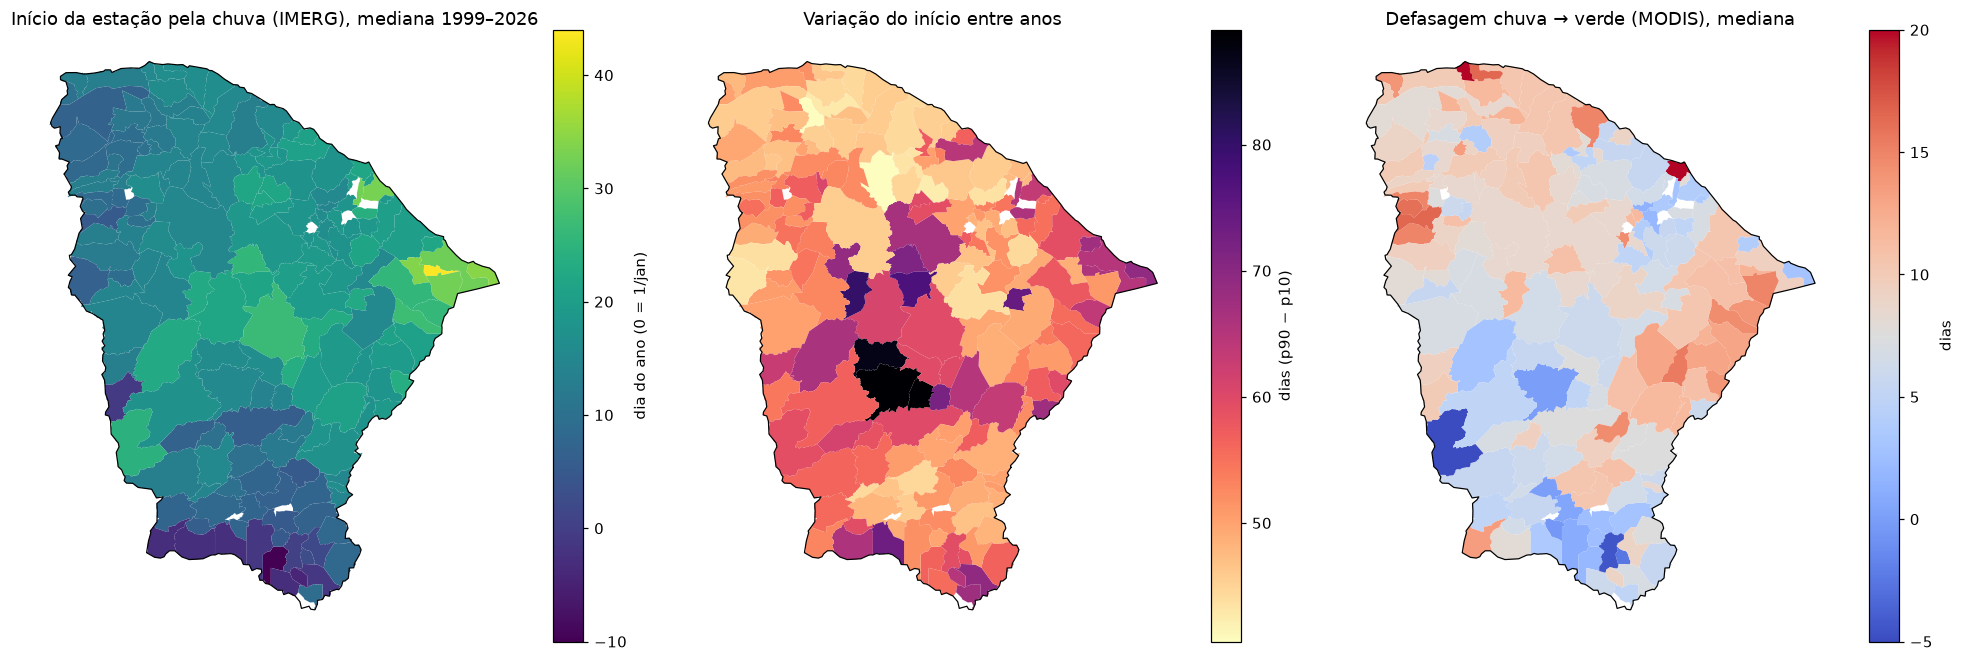

In [6]:
O = pd.read_csv(D_APR / "onset_sos_mun.csv", dtype={"cod": str}, parse_dates=["inicio_chuva", "inicio_verde"])
# dia do ano; dezembro vira negativo (ex.: 15/dez = -16) para a estação ficar contínua
O["doy_chuva"] = np.where(O.inicio_chuva.dt.month == 12, O.inicio_chuva.dt.dayofyear - 365, O.inicio_chuva.dt.dayofyear)
O["doy_verde"] = np.where(O.inicio_verde.dt.month == 12, O.inicio_verde.dt.dayofyear - 365, O.inicio_verde.dt.dayofyear)
O["defasagem_dias"] = O.doy_verde - O.doy_chuva
idx = pd.read_csv(DADOS / "el_nino_2026" / "eventos.csv", index_col=0)
fortes = set(idx[idx.ONI_OND_NDJ >= 1.5].quadra_afetada.astype(int))
lanina = set(idx[idx.ONI_OND_NDJ <= -0.8].quadra_afetada.astype(int))
O["fase"] = np.where(O.ano.isin(fortes), "El Niño forte", np.where(O.ano.isin(lanina), "La Niña", "outros"))
print(f"{O.cod.nunique()} municípios × {O.ano.nunique()} anos; início pela chuva não ocorreu até 31/mai em {O.inicio_chuva.isna().mean():.0%} dos município-anos")

med = O.groupby("cod")[["doy_chuva", "doy_verde", "defasagem_dias"]].median()
var = O.groupby("cod").doy_chuva.agg(lambda s: s.quantile(0.9) - s.quantile(0.1)).rename("amplitude_p10_p90")
geo = municipios_ce_gdf().assign(cod=lambda g: g.codarea.astype(str)).merge(med.join(var), on="cod")
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
geo.plot(column="doy_chuva", ax=axs[0], cmap="viridis", legend=True, legend_kwds={"label": "dia do ano (0 = 1/jan)"})
axs[0].set_title("Início da estação pela chuva (IMERG), mediana 1999–2026")
geo.plot(column="amplitude_p10_p90", ax=axs[1], cmap="magma_r", legend=True, legend_kwds={"label": "dias (p90 − p10)"})
axs[1].set_title("Variação do início entre anos")
geo.plot(column="defasagem_dias", ax=axs[2], cmap="coolwarm", legend=True, legend_kwds={"label": "dias"})
axs[2].set_title("Defasagem chuva → verde (MODIS), mediana")
for a in axs:
    ceara_gdf().boundary.plot(ax=a, color="k", lw=0.8)
    a.set_axis_off()
plt.tight_layout()
plt.show()

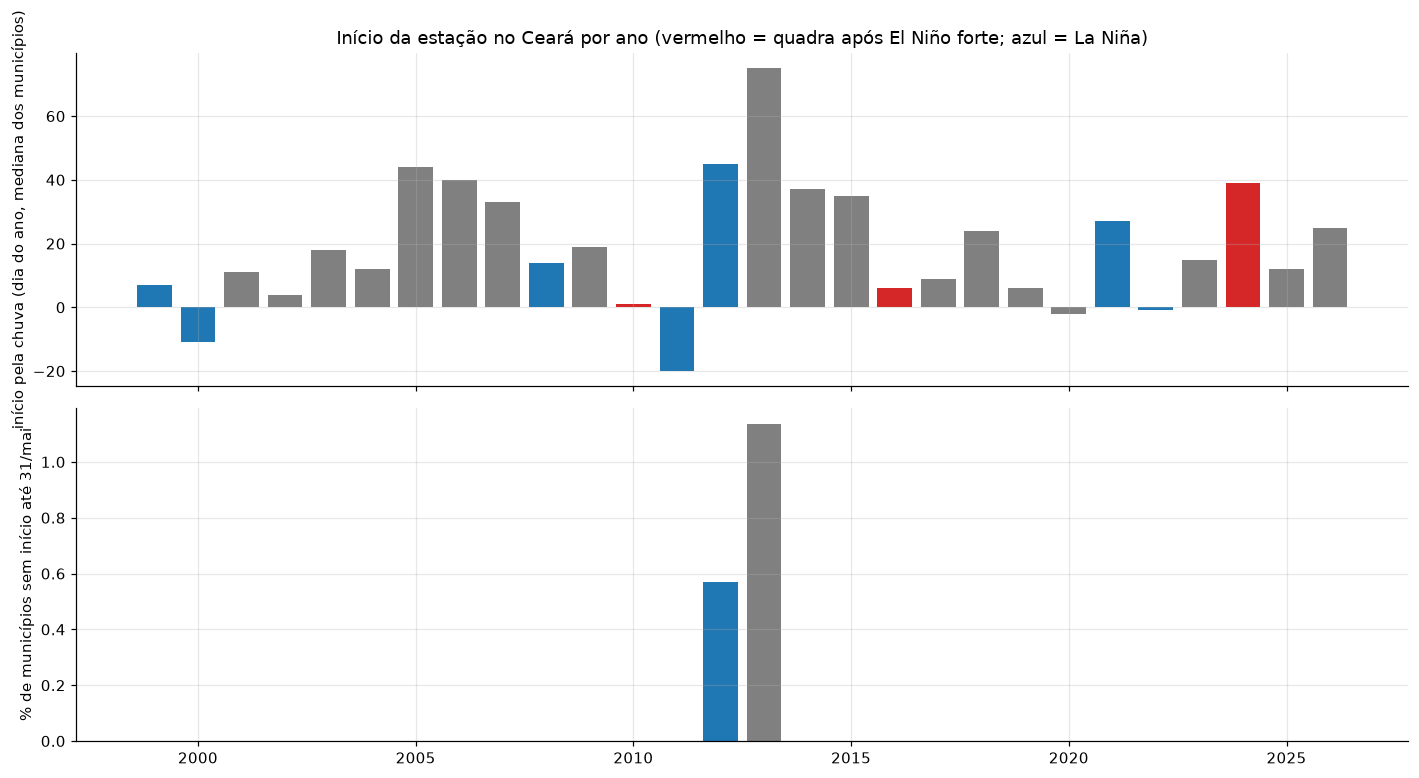

,inicio_chuva_mediana,sem_inicio_pct,inicio_verde_mediana,defasagem_mediana,n
fase,,,,,
El Niño forte,6.0,0.0,17.0,11.0,528
La Niña,7.0,0.1,17.0,7.0,1232
outros,18.0,0.1,33.0,8.0,3168


Mann-Whitney (início pela chuva, El Niño forte × outros, município-anos): p = 5.64e-31 (atenção: município-anos do mesmo ano não são independentes; a unidade honesta é o ano)
Por ano: mediana do início em El Niño forte = dia 6 (n = 3); outros = dia 18 (n = 18)


In [7]:
est = O.groupby("ano").agg(inicio_chuva=("doy_chuva", "median"), sem_inicio=("inicio_chuva", lambda s: s.isna().mean() * 100),
                            inicio_verde=("doy_verde", "median"), chuva_fev_mai=("chuva_fev_mai_mm", "median"))
est["fase"] = ["El Niño forte" if a in fortes else ("La Niña" if a in lanina else "outros") for a in est.index]
fig, axs = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
cores = {"El Niño forte": "tab:red", "La Niña": "tab:blue", "outros": "gray"}
axs[0].bar(est.index, est.inicio_chuva, color=[cores[f] for f in est.fase])
axs[0].set_ylabel("início pela chuva (dia do ano, mediana dos municípios)")
axs[0].set_title("Início da estação no Ceará por ano (vermelho = quadra após El Niño forte; azul = La Niña)")
axs[1].bar(est.index, est.sem_inicio, color=[cores[f] for f in est.fase])
axs[1].set_ylabel("% de municípios sem início até 31/mai")
plt.tight_layout()
plt.show()
comp = O.groupby("fase").agg(inicio_chuva_mediana=("doy_chuva", "median"), sem_inicio_pct=("inicio_chuva", lambda s: round(s.isna().mean() * 100, 1)),
                              inicio_verde_mediana=("doy_verde", "median"), defasagem_mediana=("defasagem_dias", "median"), n=("cod", "count"))
display(comp)
from scipy.stats import mannwhitneyu
a = O[O.fase == "El Niño forte"].doy_chuva.dropna()
b = O[O.fase == "outros"].doy_chuva.dropna()
print(f"Mann-Whitney (início pela chuva, El Niño forte × outros, município-anos): p = {mannwhitneyu(a, b).pvalue:.3g}"
      " (atenção: município-anos do mesmo ano não são independentes; a unidade honesta é o ano)")
ea = est[est.fase == "El Niño forte"].inicio_chuva
eo = est[est.fase == "outros"].inicio_chuva
print(f"Por ano: mediana do início em El Niño forte = dia {ea.median():.0f} (n = {len(ea)}); outros = dia {eo.median():.0f} (n = {len(eo)})")

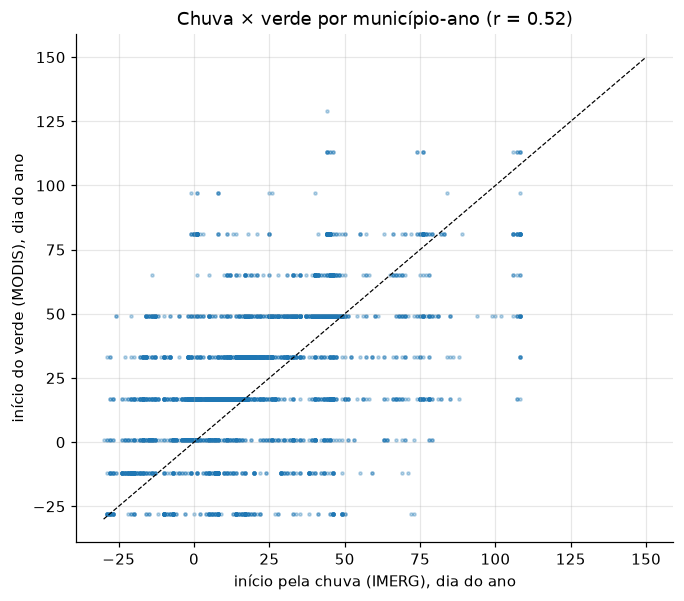

In [8]:
r = O.dropna(subset=["doy_chuva", "doy_verde"])
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(r.doy_chuva, r.doy_verde, s=4, alpha=0.3)
ax.plot([-30, 150], [-30, 150], "k--", lw=0.8)
ax.set_xlabel("início pela chuva (IMERG), dia do ano")
ax.set_ylabel("início do verde (MODIS), dia do ano")
ax.set_title(f"Chuva × verde por município-ano (r = {r.doy_chuva.corr(r.doy_verde):.2f})")
plt.show()

**Leitura e uso no produto:**
- **O portão de janeiro e fevereiro ganha uma data local:** o início pela chuva, por município, com a faixa de
  variação entre anos. Plantar antes do "início verdadeiro" (sem veranico logo depois) é o falso início que
  queima semente.
- **O verde do MODIS confirma o início pela chuva com uma defasagem medida** (mapa à direita). No produto, o NDVI do
  VIIRS/HLS faz essa confirmação no talhão, quando a nuvem deixar.
- **O El Niño forte NÃO atrasou o início.** Nos 3 anos de El Niño forte da série (2010, 2016 e 2024), o início pela
  chuva veio **antes**: mediana no dia 6 contra o dia 18 nos anos neutros (sem La Niña); contra todos os demais anos, dia 15.
  - São **janeiros chuvosos seguidos de quadra fraca**, o falso início em escala de estação. É o mesmo "janeiro engana"
    da rodada 2 do conselho.
  - **O início da chuva sozinho não protege em ano de El Niño.** Por isso a QUADRA decide nos portões de 19/mar e
    30/abr (chuva desde 1/fev e SMAP), e não só no início.
  - A comparação honesta é por **ano** (n = 3 contra 18). Os municípios de um mesmo ano não são independentes, então o
    p do Mann-Whitney por município-ano é otimista.
- Ficam de fora 8 municípios pequenos, que não contêm o centro de nenhuma célula de 0,1° do IMERG.
- **Global:** a regra usa só a chuva diária do IMERG, que existe para todo o planeta. Ela conversa com os calendários
  globais (Sacks 2010, MIRCA2000, WorldCereal) para checagem.

## 6. Como isso entra no motor da QUADRA: o catálogo de rotações ponderado pelo clima

O catálogo de rotações comprovadas (`pesquisa/catalogo_rotacoes.json`) reúne 147 configurações. Foram debatidas
por 10 especialistas e passaram por verificação adversária. Cada cartão traz:
- o **efeito** (cultura seguinte, sequência inteira, consórcio, solo ou praga);
- o **grau** (A–D);
- a **transferência** para o semiárido (T0 = medido no semiárido brasileiro; T1 = estrato análogo; T2 = só direção;
  T3 = não transfere).

Aqui somamos o terceiro eixo, **medido com a NASA:** a semelhança entre o clima do lugar do estudo e o clima de cada
município, pela assinatura do POWER das seções 1 a 3.

**Recibo de evidência ponderado pelo clima, para cada estratégia e município:**
1. **Filtro de aptidão (GAEZ):** a cultura cabe no município (seção 4)?
2. **Data de plantio (IMERG):** o início típico e a faixa do município (seção 5), atualizados nos portões.
3. **Efeito esperado:** a média dos cartões do catálogo, ponderada por w = exp(−d²/2) entre o município e o lugar de
   cada estudo. Só os cartões T0 e T1 entram com número; T2 entra só como direção.
4. **Confiança:** se o melhor estudo tem w < 0,3, o recibo diz "nenhum estudo de clima parecido" e rebaixa o grau.

In [9]:
import json
import re
from pathlib import Path

CAT = json.loads(Path(r"c:\Users\netinhoklz\Projetos pessoais\campeonato-nasa\pesquisa\catalogo_rotacoes.json").read_text(encoding="utf-8"))
C = pd.DataFrame(CAT["configuracoes"]).merge(pd.read_csv(D_APR / "catalogo_cartao_lugar.csv"), on="id")
LA = pd.read_csv(D_APR / "catalogo_lugares_assinaturas.csv")


def pct_relativo(c):
    """Efeito em % do controle: o pct do cartão; em t/ha, divide pelo rendimento do controle impresso no texto."""
    e = c["efeito"] or {}
    if e.get("pct") and e["pct"][0] is not None:
        return pd.Series(e["pct"][:3], dtype=float)
    m = re.search(r"(\d+,\d+) → (\d+,\d+) t/ha", c["efeito_texto"] or "")
    if e.get("unidade") == "t/ha" and m:
        b = float(m.group(1).replace(",", "."))
        return pd.Series([100 * (e.get(k) if e.get(k) is not None else np.nan) / b for k in ("central", "baixo", "alto")], dtype=float)
    return pd.Series([np.nan] * 3)


C[["pct", "pct_baixo", "pct_alto"]] = C.apply(pct_relativo, axis=1)
LA["d_quixada"] = dist(za, z(LA))
LA["w_quixada"] = np.exp(-LA.d_quixada ** 2 / 2)
C = C.merge(LA[["lugar", "d_quixada", "w_quixada"]], on="lugar", how="left")
C["classe_w"] = pd.cut(C.w_quixada, [-0.01, 0.3, 0.6, 1.01], labels=["w < 0,3", "0,3 ≤ w < 0,6", "w ≥ 0,6"]).astype(str)
C.loc[C.lugar.isna(), "classe_w"] = "sem lugar (global ou região)"
print(f"{len(C)} cartões; {C.lugar.notna().sum()} com lugar identificável ({C.lugar.nunique()} lugares)")
display(pd.crosstab(C.tipo, C.transferencia, margins=True, margins_name="total"))

147 cartões; 72 com lugar identificável (31 lugares)


transferencia,T0,T1,T2,T3,total
tipo,,,,,
agrofloresta,8,0,1,1,10
cobertura,9,0,6,7,22
consorcio,11,0,4,1,16
ilp,3,0,1,0,4
modulador,0,2,10,1,13
quebra_de_praga,4,0,12,1,17
rotacao,0,5,39,20,64
sucessao,1,0,0,0,1
total,36,7,73,31,147


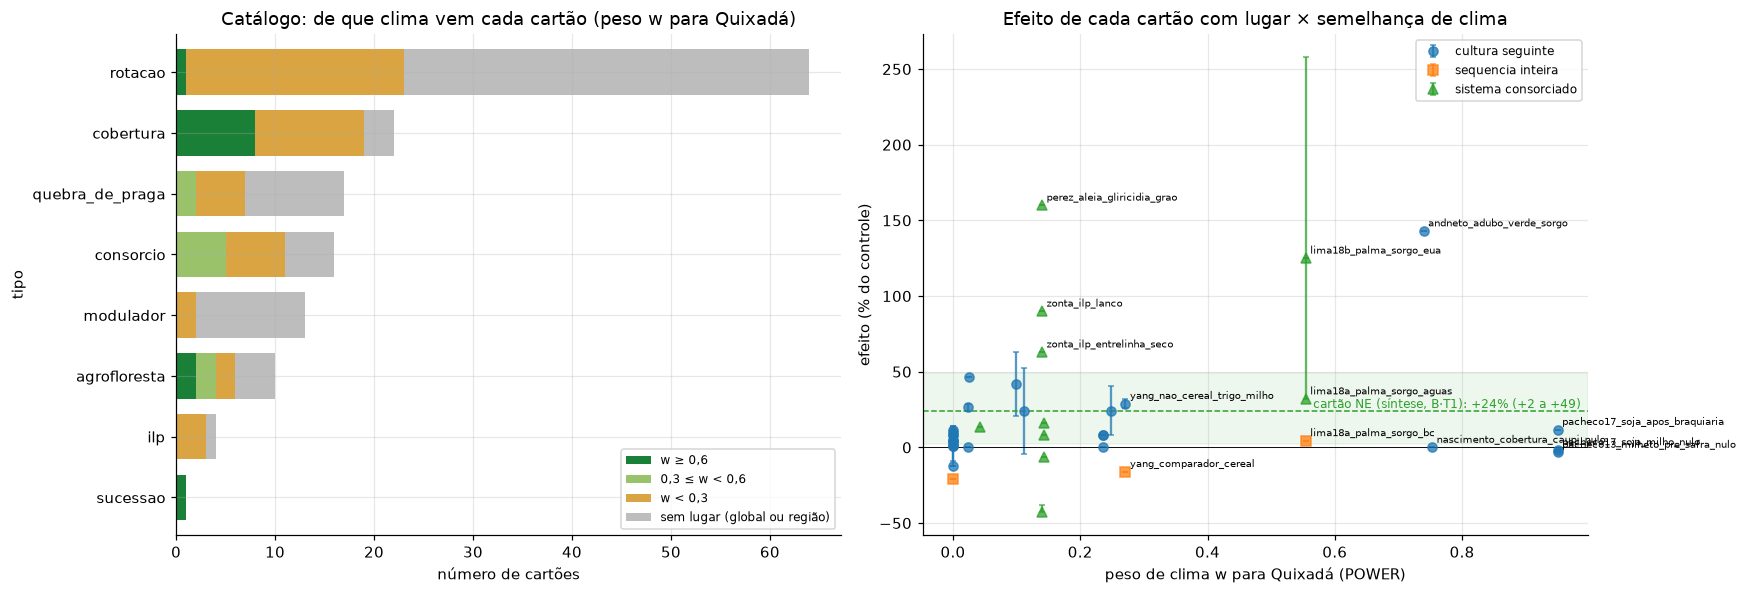

In [10]:
ordem = ["w ≥ 0,6", "0,3 ≤ w < 0,6", "w < 0,3", "sem lugar (global ou região)"]
cores_w = {"w ≥ 0,6": "#1a7f37", "0,3 ≤ w < 0,6": "#9ac26b", "w < 0,3": "#d9a441", "sem lugar (global ou região)": "#bdbdbd"}
T = pd.crosstab(C.tipo, C.classe_w).reindex(columns=ordem, fill_value=0)
T = T.loc[T.sum(1).sort_values().index]
fig, axs = plt.subplots(1, 2, figsize=(16, 5.5))
T.plot.barh(stacked=True, ax=axs[0], color=[cores_w[c] for c in ordem], width=0.75)
axs[0].set_xlabel("número de cartões")
axs[0].set_title("Catálogo: de que clima vem cada cartão (peso w para Quixadá)")
axs[0].legend(fontsize=8, loc="lower right")
P = C.dropna(subset=["pct", "w_quixada"])
P = P[P.efeito.map(lambda e: (e or {}).get("na") in ("cultura_seguinte", "sequencia_inteira", "sistema_consorciado"))]
marc = {"cultura_seguinte": "o", "sequencia_inteira": "s", "sistema_consorciado": "^"}
for na, g in P.groupby(P.efeito.map(lambda e: e["na"])):
    err = np.vstack([(g.pct - g.pct_baixo).clip(lower=0).fillna(0), (g.pct_alto - g.pct).clip(lower=0).fillna(0)])
    axs[1].errorbar(g.w_quixada, g.pct, yerr=err, fmt=marc[na], ms=6, alpha=0.75, capsize=2, label=na.replace("_", " "))
lg = next(c for c in CAT["configuracoes"] if c["id"] == "ne_lg_cereal_sequeiro_quente")["efeito"]["pct"]
axs[1].axhspan(lg[1], lg[2], color="tab:green", alpha=0.08)
axs[1].axhline(lg[0], color="tab:green", ls="--", lw=1)
axs[1].text(0.99, lg[0] + 2, f"cartão NE (síntese, B·T1): +{lg[0]:.0f}% ({lg[1]:+.0f} a {lg[2]:+.0f})", ha="right", fontsize=8, color="tab:green",
            transform=axs[1].get_yaxis_transform())
for _, r in P[(P.w_quixada > 0.25) | (P.pct.abs() > 60)].iterrows():
    axs[1].annotate(r.id, (r.w_quixada, r.pct), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
axs[1].axhline(0, color="k", lw=0.6)
axs[1].set_xlabel("peso de clima w para Quixadá (POWER)")
axs[1].set_ylabel("efeito (% do controle)")
axs[1].set_title("Efeito de cada cartão com lugar × semelhança de clima")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [11]:
cols = ["id", "tipo", "configuracao", "pct", "pct_baixo", "pct_alto", "grau", "transferencia", "lugar", "w_quixada"]
print("Cartões com clima parecido com o de Quixadá (w ≥ 0,3), do mais parecido ao menos:")
display(C[C.w_quixada >= 0.3].sort_values("w_quixada", ascending=False)[cols].round(2))
print("Lugares de estudo do catálogo, do mais parecido ao menos parecido com Quixadá:")
display(LA.sort_values("d_quixada")[["lugar", "chuva_anual_mm", "aridez_P_ET0", "meses_umidos", "d_quixada", "w_quixada"]].round(2))

Cartões com clima parecido com o de Quixadá (w ≥ 0,3), do mais parecido ao menos:


,id,tipo,configuracao,pct,pct_baixo,pct_alto,grau,transferencia,lugar,w_quixada
63,pacheco17_soja_milho_nulo,rotacao,Soja (+milheto) → milho + braquiária contra mi...,-1.6,NaN,NaN,C,T2,Bom Jesus-PI,0.95
80,pacheco13_milheto_pre_safra_nulo,cobertura,Milheto pré-safra (out) antes da soja — nulo c...,-3.3,NaN,NaN,C,T3,Bom Jesus-PI,0.95
79,pacheco13_milheto_pos_colheita_falha,cobertura,ALERTA: milheto semeado logo após a colheita d...,2.7,NaN,NaN,C,T2,Bom Jesus-PI,0.95
78,pacheco13_sobressemeadura_massa,cobertura,Sobressemeadura de braquiária ou milheto na so...,140.0,127.0,167.0,C,T3,Bom Jesus-PI,0.95
77,pacheco17_soja_apos_braquiaria,cobertura,Soja após U. ruziziensis sobressemeada na soja...,11.8,NaN,NaN,C,T3,Bom Jesus-PI,0.95
84,palhada_meia_vida,cobertura,Persistência da palhada: Cerrado quente (PI) c...,NaN,NaN,NaN,C,T2,Bom Jesus-PI,0.95
64,neves_sucessao_sal,sucessao,Sucessão caupi irrigado com água salina (seca)...,NaN,NaN,NaN,C,T0,Pentecoste-CE,0.77
72,nascimento_cobertura_caupi_nulo,cobertura,Mucuna ou milheto por 60 d antes do caupi — nu...,0.0,NaN,NaN,C,T0,Crato-CE,0.75
73,andneto_adubo_verde_sorgo,cobertura,Adubos verdes por 90 d antes do sorgo forragei...,143.0,NaN,NaN,D,T0,Mossoró-RN,0.74
74,miranda_fotoperiodo,cobertura,Crotalária juncea: teto de biomassa por fotope...,NaN,NaN,NaN,C,T0,Mossoró-RN,0.74


Lugares de estudo do catálogo, do mais parecido ao menos parecido com Quixadá:


,lugar,chuva_anual_mm,aridez_P_ET0,meses_umidos,d_quixada,w_quixada
9,Bom Jesus-PI,806.0,0.36,5,0.32,0.95
10,Pentecoste-CE,897.0,0.44,5,0.72,0.77
12,Crato-CE,901.0,0.43,5,0.75,0.75
13,Mossoró-RN,708.0,0.30,4,0.78,0.74
22,Taperoá-PB,661.0,0.30,4,0.91,0.66
25,Oeste da Bahia (aprox.),893.0,0.45,6,1.02,0.59
20,Serra Talhada-PE,670.0,0.31,4,1.09,0.55
23,Sobral-CE,958.0,0.49,5,1.12,0.53
27,Barbalha-CE,815.0,0.50,5,1.22,0.48
4,Luancheng-China,512.0,0.46,3,1.62,0.27


**Leitura:**
- **72 dos 147 cartões têm um lugar identificável** (31 lugares). Os outros são médias globais ou de continente, que
  já entram só como direção (T2/T3).
- **Lugares mais parecidos com Quixadá:** Bom Jesus-PI (w 0,95), Pentecoste (0,77), Crato (0,75), Mossoró (0,74),
  Taperoá (0,66), Oeste da Bahia (0,59) e Serra Talhada (0,55).
- **Os celeiros temperados têm w = 0,00:** Corn Belt, Europa, Ontário e Pradarias. A regra do catálogo ("número só
  com T0 ou T1") agora tem uma medida da NASA por trás.
- **21 cartões vêm de clima parecido (w ≥ 0,3), mas nenhum deles é de rotação no tempo medida no semiárido
  brasileiro.**
  - Os do Nordeste são de cobertura, consórcio (palma + sorgo), agrofloresta (gliricídia) e praga (bicudo).
  - **Nenhum número de rotação (T0 ou T1) vem de clima parecido.** O Franke da África Austral (+42%) caiu para
    w 0,10 e saiu da lista.
  - O único cartão de rotação com w ≥ 0,3 é o soja → milho de Bom Jesus-PI (−1,6%, nulo, T2, w 0,95). Entra só como
    direção.
- **No gráfico de dispersão, os efeitos acima de +100% são biomassa de cobertura, não grão.** É o caso da
  sobressemeadura de Pacheco 2013 e dos adubos verdes irrigados de Mossoró.

### A lacuna, no mapa: onde está o estudo de rotação mais parecido com cada município?
- **Painel da esquerda:** quantos cartões do catálogo vêm de um clima parecido (w ≥ 0,3) com o de cada município. É a
  densidade de evidência aplicável.
- **Painel do meio:** o peso w do **ensaio de rotação no tempo** (cartão do tipo rotação, efeito na cultura seguinte)
  de clima mais parecido.
- **Painel da direita:** o lugar desse ensaio.

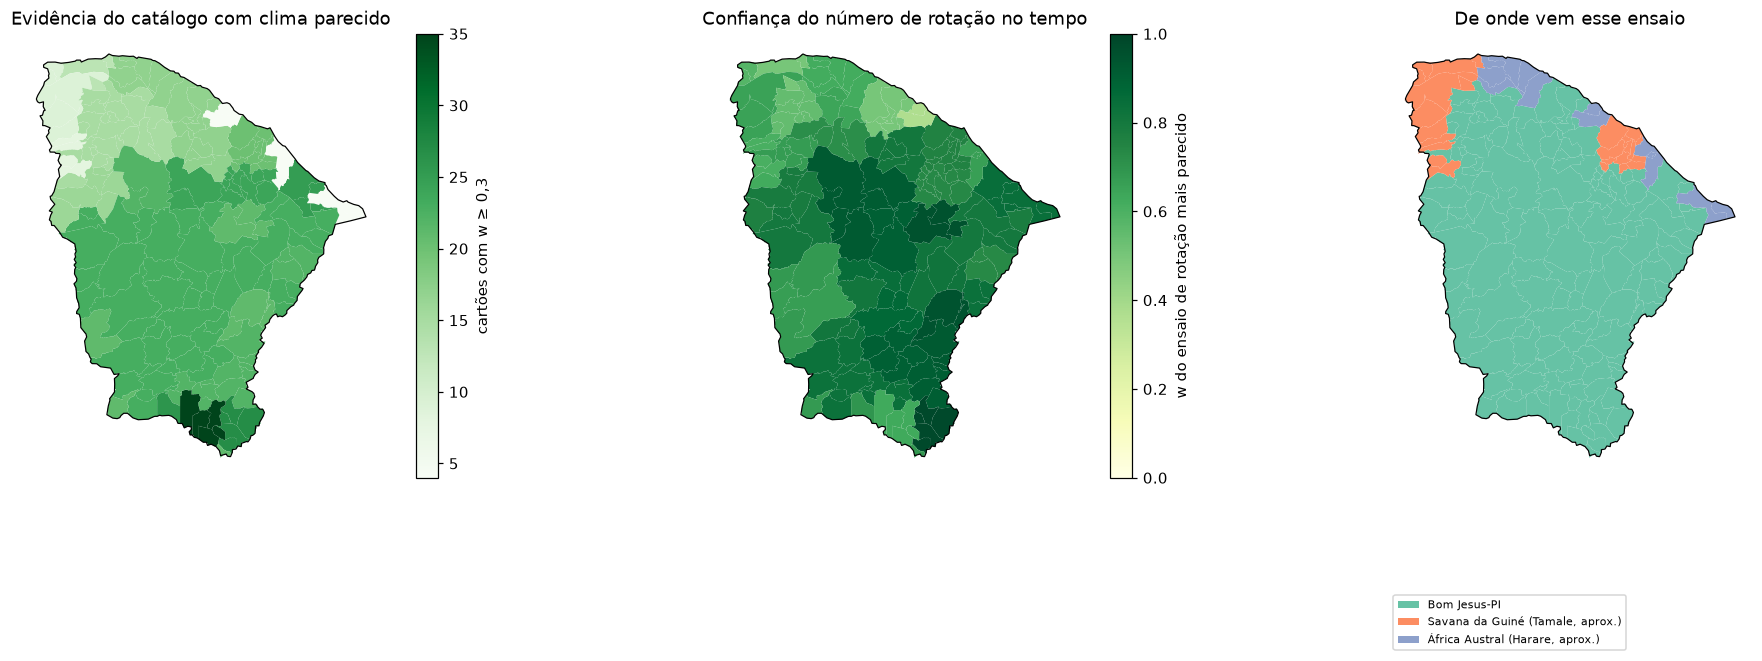

Cartões de rotação no tempo com lugar: beal_cohen_milho_satelite, bowles_akron_pousio, bowles_pior_ambiente, franke_austral, franke_guine, franke_sahel, gaudin_elora, kluger_leg_trigo_primavera, kluger_milho_soja, kluger_neg_soja_trigo_inverno, kluger_outros_pares_temperados, kluger_pousio_trigo, kluger_soja_milho, marini_europa, pacheco17_soja_milho_nulo, renwick_seca_imposta, seifert_milho_continuo, seifert_soja_continua, smith_graos_pequenos, yang_nao_cereal_trigo_milho, zhou_corn_belt


,cartoes_w03,w_rotacao,lugar_rotacao
mesorregiao,,,
Centro-Sul Cearense,23.0,0.90,Bom Jesus-PI
Jaguaribe,23.0,0.83,Bom Jesus-PI
Metropolitana de Fortaleza,20.0,0.75,"Savana da Guiné (Tamale, aprox.)"
Noroeste Cearense,15.0,0.65,Bom Jesus-PI
Norte Cearense,17.0,0.68,Bom Jesus-PI
Sertões Cearenses,23.0,0.82,Bom Jesus-PI
Sul Cearense,23.0,0.81,Bom Jesus-PI


In [12]:
zl = z(LA)
WM = np.exp(-np.array([dist(zm.iloc[i], zl) for i in range(len(M))]) ** 2 / 2)  # municípios × lugares
WM = pd.DataFrame(WM, columns=LA.lugar.values, index=M.cod.values)
lug_card = C.dropna(subset=["lugar"])
M["cartoes_w03"] = [(WM.loc[c, lug_card.lugar].values >= 0.3).sum() for c in M.cod]
rot = C[(C.tipo == "rotacao") & C.lugar.notna() & C.efeito.map(lambda e: (e or {}).get("na") == "cultura_seguinte")]
lug_rot = rot.lugar.unique()
M["w_rotacao"] = WM[lug_rot].max(1).values
M["lugar_rotacao"] = WM[lug_rot].idxmax(1).values
geo = municipios_ce_gdf().assign(cod=lambda g: g.codarea.astype(str)).merge(M, on="cod")
fig, axs = plt.subplots(1, 3, figsize=(19, 6.5))
geo.plot(column="cartoes_w03", ax=axs[0], cmap="Greens", legend=True, legend_kwds={"label": "cartões com w ≥ 0,3"})
axs[0].set_title("Evidência do catálogo com clima parecido")
geo.plot(column="w_rotacao", ax=axs[1], cmap="YlGn", vmin=0, vmax=1, legend=True, legend_kwds={"label": "w do ensaio de rotação mais parecido"})
axs[1].set_title("Confiança do número de rotação no tempo")
geo.plot(column="lugar_rotacao", ax=axs[2], categorical=True, legend=True, cmap="Set2",
         legend_kwds={"fontsize": 7, "loc": "lower left", "bbox_to_anchor": (0, -0.4)})
axs[2].set_title("De onde vem esse ensaio")
for a in axs:
    ceara_gdf().boundary.plot(ax=a, color="k", lw=0.8)
    a.set_axis_off()
plt.tight_layout()
plt.show()
print("Cartões de rotação no tempo com lugar:", ", ".join(sorted(rot.id)))
display(M.groupby("mesorregiao").agg(cartoes_w03=("cartoes_w03", "median"), w_rotacao=("w_rotacao", "mean"),
                                    lugar_rotacao=("lugar_rotacao", lambda s: s.value_counts().index[0])).round(2))

**Leitura:**
- **O ensaio de rotação no tempo mais parecido com cada município fica fora do Ceará:**
  - **Centro-Sul, Jaguaribe, Sertões, Sul, Noroeste e Norte:** Bom Jesus-PI, com soja → milho no Cerrado (w médio de
    0,65 no Noroeste a 0,90 no Centro-Sul). O efeito foi nulo e o cartão é T2.
  - **Região Metropolitana de Fortaleza:** o Franke da Savana da Guiné (Tamale), w 0,75.
  - O Franke da África Austral não é mais o ensaio mais parecido de nenhuma mesorregião.
- **Cada mesorregião tem de 15 a 23 cartões de clima parecido** (mediana por município), quase todos de consórcio,
  cobertura, agrofloresta e praga.
- **É a lacuna que mais muda o ranking do motor:** a passagem da prática atual (S0) para a rotação no tempo nunca foi
  medida (cartão `ne_s0_para_rotacao_tempo`, D·T3, de 0 a +9%). O experimento mais barato que responde a isso é o de
  faixas que trocam de lugar a cada ano, num município do sertão.

### Leguminosa antes do cereal: quanto esperar em cada região do Ceará?
Os três estratos do Franke (2018), os únicos cartões de leguminosa → cereal com lugar e transferência T1, são
ponderados pelo peso de clima de cada município. Ficam lado a lado com o cartão-síntese do Nordeste.

In [13]:
fr = C[C.id.isin(["franke_sahel", "franke_guine", "franke_austral"])].set_index("id")
Wf = WM[fr.lugar.values].values
M["leg_cereal_pct"] = (Wf * fr.pct.values[None, :]).sum(1) / Wf.sum(1)
M["soma_w_franke"] = Wf.sum(1)
display(fr[["configuracao", "pct", "pct_baixo", "pct_alto", "grau", "transferencia", "lugar", "w_quixada"]].round(2))
display(M.groupby("mesorregiao").agg(efeito_ponderado_pct=("leg_cereal_pct", "mean"), soma_dos_pesos=("soma_w_franke", "mean")).round(2))
q = M.loc[M.municipio.str.contains("Quixadá"), ["leg_cereal_pct", "soma_w_franke"]].iloc[0]
print(f"Quixadá: leguminosa → cereal ponderada pelo clima = +{q.leg_cereal_pct:.0f}% (soma dos pesos {q.soma_w_franke:.2f}); "
      f"cartão NE = +{lg[0]:.0f}% ({lg[1]:+.0f} a {lg[2]:+.0f}). Só no ano colhido; contra a S0 (consórcio), não medido.")

,configuracao,pct,pct_baixo,pct_alto,grau,transferencia,lugar,w_quixada
id,,,,,,,,
franke_sahel,Leguminosa → cereal na zona sudano-saheliana (...,24.14,-4.31,52.59,C,T1,"Sahel (Niamey, aprox.)",0.11
franke_guine,Leguminosa → cereal na savana da Guiné (700–1....,24.30,7.94,40.65,B,T1,"Savana da Guiné (Tamale, aprox.)",0.25
franke_austral,Leguminosa → milho nas savanas da África Austr...,41.82,20.61,63.03,B,T1,"África Austral (Harare, aprox.)",0.10


,efeito_ponderado_pct,soma_dos_pesos
mesorregiao,,
Centro-Sul Cearense,29.22,0.54
Jaguaribe,30.35,0.52
Metropolitana de Fortaleza,28.86,0.93
Noroeste Cearense,29.40,0.72
Norte Cearense,30.59,0.82
Sertões Cearenses,30.57,0.50
Sul Cearense,31.49,0.68


Quixadá: leguminosa → cereal ponderada pelo clima = +28% (soma dos pesos 0.46); cartão NE = +24% (+2 a +49). Só no ano colhido; contra a S0 (consórcio), não medido.


**Leitura:**
- **Ponderado pelo clima, o efeito da leguminosa antes do cereal em Quixadá fica em cerca de +28%** (soma dos pesos
  0,46). Entre as mesorregiões, vai de +29% a +31%.
  - Quem mais pesa é a Savana da Guiné (+24%, w 0,25).
  - O Sahel (+24%, não significativo) pesa 0,11.
  - A África Austral (+42%) pesa só 0,10.
- **Ressalva: o motor fica com o cartão-síntese de +24% (de +2% a +49%) como número central** e usa os +28% só como
  sensibilidade. O motivo é que nenhum dos três estratos vem de clima parecido com o de Quixadá: todos têm w < 0,3
  (o maior é 0,25). Pela regra do recibo, isso rebaixa o grau.
- **Os dois números valem só no ano colhido e só contra milho solteiro:**
  - o milho quebra em 20,2% dos município-anos do Ceará (2000–2024);
  - contra a prática atual (milho + feijão consorciados), o efeito não foi medido.

### Conclusões deste aprofundamento
- **A evidência certa para o Ceará vem de climas parecidos, e a NASA permite medir essa semelhança em qualquer lugar.**
  Os melhores análogos do sertão são o Cerrado piauiense, o semiárido da Índia (Patancheru), Serra Talhada e Sobral,
  não os celeiros temperados onde a rotação foi medida por satélite (w = 0,00).
- **A ordem dos análogos é robusta** (seção 1). O Cerrado piauiense fica entre os 3 mais parecidos com o Sertão
  Central em 100% de 2.000 sorteios de pesos, e o semiárido da Índia em 98,6%. Tirando qualquer variável, a
  concordância da ordem fica entre 0,85 e 0,92 (tau de Kendall).
- **Cada município puxa uma literatura diferente** (seção 2), então o recibo do produto é municipal.
- **O "sertão no mundo"** (seção 3) mostra onde mais a ferramenta funciona do mesmo jeito: Chaco argentino, Oeste da
  Bahia, norte da Austrália, Burkina Faso, sudoeste de Madagascar e o Deccan na Índia.
- **Clima parecido também traz culturas parecidas** (seção 4, Spearman −0,76). Os 5 análogos mais próximos têm todos
  perfil de culturas parecido. Harare, que tem culturas diferentes, deixou de ser análogo. O motor continua exigindo
  as duas coisas.
- **Armadilha do El Niño** (seção 5): nos anos de El Niño forte, a chuva "começou" mais cedo (dia 6 contra 18) e a
  quadra falhou. O início da estação não basta; quem decide são os portões de março e abril (chuva desde 1/fev e SMAP).
- **O catálogo ponderado pelo clima** (esta seção) chega a três conclusões:
  - os números que valem no sertão vêm só do próprio Nordeste (consórcio, cobertura, agrofloresta, praga). A
    leguminosa → cereal do Franke chega a Quixadá com w ≤ 0,25 e fica só como sensibilidade;
  - nenhum ensaio de rotação no tempo foi feito em clima de sertão. O de clima mais parecido (soja → milho em Bom
    Jesus-PI, w 0,95) é do Cerrado, deu efeito nulo e é T2;
  - o ensaio de faixas que trocam de lugar é a medida que falta.